In [1]:
import numpy as np
import pandas as pd
import geopandas as gpd
from sklearn.neighbors import NearestNeighbors
import statsmodels.api as sm
from scipy.stats import ttest_ind

import libpysal
import spreg 

import matplotlib.pyplot as plt
import seaborn as sns


# Modelos Espaciais de Inferência Causal
## Propensity Score Matching (PSM) e Inverse Probability Weighting (IPW)

### Arquivos

Utilizaremos dados sobre homicídios e características socioeconômicas selecionadas para os condados dos EUA continental. Os dados abrangem quatro anos de censo decenal: 1960, 1970, 1980 e 1990:

- **NAT.shp,shx,dbf,prj**: homicídios e características socioeconômicas selecionadas para 3.085 condados dos EUA continental.

Você pode encontrar mais informações sobre os dados aqui: https://geodacenter.github.io/data-and-lab/ncovr/

Leremos o shapefile da mesma forma que antes, usando a função `read_file`, seguida pelo caminho do arquivo entre parênteses.

In [2]:
libpysal.examples.load_example('NCOVR')
shp_path = libpysal.examples.get_path('NAT.shp')
dfs = gpd.read_file(shp_path)

print('NAT rows:', len(dfs), '| columns:', len(dfs.columns))
dfs.head()

NAT rows: 3085 | columns: 70


,NAME,STATE_NAME,STATE_FIPS,CNTY_FIPS,FIPS,STFIPS,COFIPS,FIPSNO,SOUTH,HR60,...,BLK90,GI59,GI69,GI79,GI89,FH60,FH70,FH80,FH90,geometry
0,Lake of the Woods,Minnesota,27,077,27077,27,77,27077,0,0.000000,...,0.024534,0.285235,0.372336,0.342104,0.336455,11.279621,5.4,5.663881,9.515860,"POLYGON ((-95.34258 48.5467, -95.34081 48.7151..."
1,Ferry,Washington,53,019,53019,53,19,53019,0,0.000000,...,0.317712,0.256158,0.360665,0.361928,0.360640,10.053476,2.6,10.079576,11.397059,"POLYGON ((-118.8505 47.94969, -118.84732 48.47..."
2,Stevens,Washington,53,065,53065,53,65,53065,0,1.863863,...,0.210030,0.283999,0.394083,0.357566,0.369942,9.258437,5.6,6.812127,10.352015,"POLYGON ((-117.43777 48.04422, -117.54113 48.0..."
3,Okanogan,Washington,53,047,53047,53,47,53047,0,2.612330,...,0.155922,0.258540,0.371218,0.381240,0.394519,9.039900,8.1,10.084926,12.840340,"POLYGON ((-118.97096 47.93928, -118.97293 47.9..."
4,Pend Oreille,Washington,53,051,53051,53,51,53051,0,0.000000,...,0.134605,0.243263,0.365614,0.358706,0.387848,8.243930,4.1,7.557643,10.313002,"POLYGON ((-117.4375 49, -117.03098 49, -117.02..."


Para reduzir o número de observações, selecionaremos apenas os condados dos estados do leste dos EUA. Também vamos selecionar somente as variáveis de nosso interesse. Buscaremos estimar o efeito causal de um condado se localizar na porção nordeste do EUA sobre sua taxa de homicídio nos anos 90. Sinta-se à vontade para rodar os exemplos usando o conjunto de dados completo.

The variables are:
| Variable | Description |
|----------|-------------|
| **FIPSNO** | FIPS code as numeric variable |
| **SOUTH** | Dummy variable for southern counties (SOUTH = 1) |
| **HR\*\*** | Homicide rate per 100,000 (1960, 1970, 1980, 1990) |
| **PS\*\*** | Population structure 1960, 1970, 1980, 1990 (principal component) |
| **UE\*\*** | Unemployment rate the years 1960, 1970, 1980, 1990 |
| **RD\*\*** | Resource deprivation the years 1960, 1970, 1980, 1990 (principal component) |
| **FH\*\*** | Percentage of female headed households 1960, 1970, 1980, 1990 |


In [3]:
east_fips = [9, 10, 11, 12, 13, 23, 24, 25, 33, 34, 36, 37, 42, 44, 45, 50, 51, 54]
dfs2 = dfs[dfs['STFIPS'].isin(east_fips)]

# Selecionando as variáveis de interesse dos anos 90
dfs2 = dfs2[['FIPSNO', 'SOUTH', 'HR90','PS90','UE90','RD90','FH90','geometry']]
print(dfs2.shape)

(789, 8)


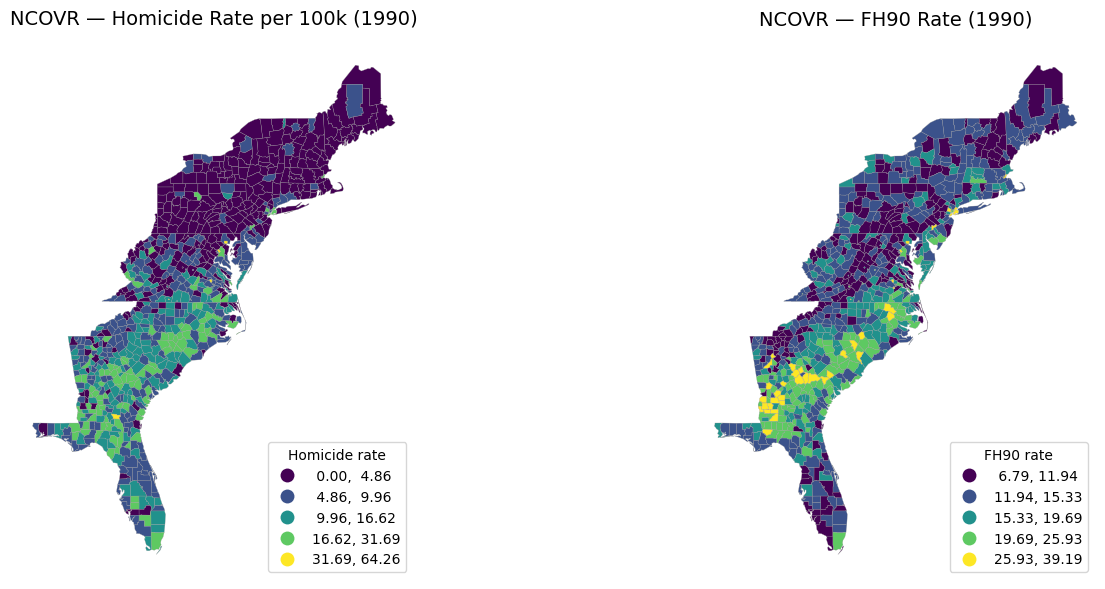

In [4]:
# Mapa das variáveis HR90 e FH90

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Primeiro subplot - HR90
dfs2.plot('HR90', scheme='NaturalBreaks', k=5,
          legend=True, edgecolor='0.6', linewidth=0.2,
          ax=ax1, legend_kwds={'title': 'Homicide rate',
                              'loc': 'lower right'})
ax1.set_title('NCOVR — Homicide Rate per 100k (1990)', fontsize=14, pad=12)
ax1.set_axis_off()

# Segundo subplot - FH90
dfs2.plot('FH90', scheme='NaturalBreaks', k=5,
          legend=True, edgecolor='0.6', linewidth=0.2,
          ax=ax2, legend_kwds={'title': 'FH90 rate',
                              'loc': 'lower right'})
ax2.set_title('NCOVR — FH90 Rate (1990)', fontsize=14, pad=12)
ax2.set_axis_off()

plt.tight_layout()
plt.show()

### Queen Contiguity Weights

Os pesos podem ser construídos da mesma forma que antes, usando o pacote `libpysal` do PySAL. A função é `weights.Queen.from_dataframe`, tendo como argumentos o geodataframe e, opcionalmente, os `ids` (recomendado).

In [5]:
wq1 = libpysal.weights.Queen.from_dataframe(dfs2,ids='FIPSNO')
wq1.transform = 'r'
wq1.n

789

### Definindo as variáveis

A especificação do modelo a ser estimado pode ser fornecida como vetores ou dataframes. Neste exemplo, a variável dependente é a variável indicadora do tratamento **NORTH**, que será a variável dependente no modelo SLX-Probit. As demais variáveis selecionadas são utilizadas para construir a matriz de regressores X.

In [6]:
dfs2['NORTH'] = 1-dfs2['SOUTH']
y_var = dfs2['NORTH']
x_var = dfs2[['RD90','PS90','UE90','FH90']]

## Propensity Score Matching (PSM)
### Estimando o modelo Probit espacial (SLX-Probit)

In [7]:
reg1 = spreg.Probit(y_var, x_var, slx_lags=1, w=wq1, spat_diag=True, 
                    name_ds="NAT.shp", name_w="Queen_1")
print(reg1.summary)

REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: CLASSIC PROBIT ESTIMATOR WITH SPATIALLY LAGGED X (SLX)
-------------------------------------------------------------------------
Data set            :     NAT.shp
Weights matrix      :     Queen_1
Dependent Variable  :       NORTH                Number of Observations:         789
True positive rate  :       85.78                Number of Variables   :           9
True negative rate  :       94.12                Degrees of Freedom    :         780
Balanced accuracy   :       89.95                Log-Likelihood        :   -153.7531
% correctly pred.   :       91.89                LR test               :    608.8115
McFadden's rho      :        0.66                LR test (p-value)     :      0.0000

------------------------------------------------------------------------------------
            Variable     Coefficient       Std.Error     z-Statistic     Probability
----------------------------------------------------------------

Como indicado em Amaral, Anselin e Arribas-Bel (2013), podemos focar no resultado do teste Kelejian-Prucha (error), que rejeita a hipótese nula de ausência de autocorrelação espacial nos resíduos do modelo Probit clássico. Ou seja, há evidências de que o modelo Probit clássico é inadequado para essa especificação e dados.

Teríamos que buscar a estimação de um modelo SDM-Probit (possível no R com o pacote spatialprobit, mas ainda não no Python). Vamos ignorar isso no momento e seguir com a estimação do modelo SLX-Probit como se a hiótese nula não tivesse sido rejeitada, apenas para fins didáticos.

#### Cálcudo do Average Treatment Effect on the Treated (ATT) via PSM

In [8]:
dfs2['propensity_score'] = reg1.predy

# Separar tratados e controles
treated = dfs2[dfs2['NORTH'] == 1]
control = dfs2[dfs2['NORTH'] == 0]

# Configurar o modelo de matching (1 vizinho mais próximo). Pode testar outros métodos.
nn = NearestNeighbors(n_neighbors=1, metric='euclidean')
nn.fit(control[['propensity_score']].values)
distances, indices = nn.kneighbors(treated[['propensity_score']].values)

# Calcular o efeito do tratamento (ATT)
treatment_effects = treated['HR90'].values - control.iloc[indices.flatten()]['HR90'].values
treatment_effect = treatment_effects.mean()
att_std_error = np.std(treatment_effects) / np.sqrt(len(treated))

print(f"Average Treatment Effect on the Treated (ATT): {treatment_effect:.4f}")
print(f"Desvio-padrão do ATT: {att_std_error:.4f}")
print(f"N tratados: {len(treated)}, N controles: {len(control)}")

Average Treatment Effect on the Treated (ATT): -2.0638
Desvio-padrão do ATT: 0.3289
N tratados: 211, N controles: 578


O Efeito Médio do Tratamento nos Tratados (ATT) de -2.0638 indica que, para o grupo que efetivamente recebeu o tratamento (as 211 unidades), o resultado foi uma redução média de aproximadamente 2.06 unidades na sua variável de resultado.

Essa interpretação se baseia na lógica contrafactual: se esse mesmo grupo de 211 tratados não tivesse recebido o tratamento, sua variável de resultado teria sido, em média, 2.06 unidades maior.

O modelo PSM tem como pressuposto a condição de suporte comum (common support) ou sobreposição, que pode ser verificada por meio de um gráfico de dispersão dos escores de propensão (propensity scores) para os grupos tratado e controle. O gráfico a seguir analisa se há suporte comum entre os dois grupos. 

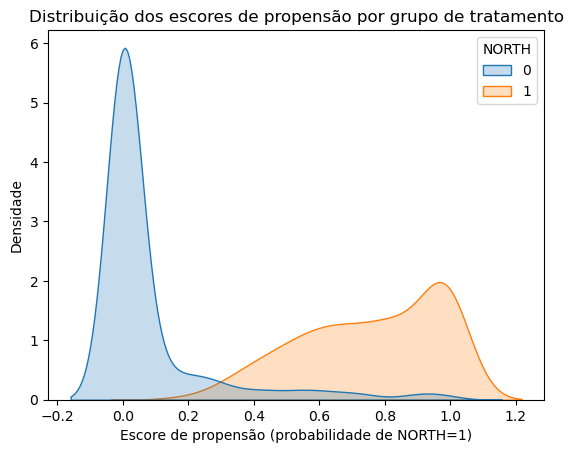

=== ESTATÍSTICAS DOS PROPENSITY SCORES ===
Tratados (NORTH=1): [0.1804, 1.0000]
Controles (NORTH=0): [0.0000, 0.9986]

Região de sobreposição: [0.1804, 0.9986]

Observações na região de sobreposição: 275/789
Taxa de sobreposição total: 34.9%
Tratados na sobreposição: 190/211 (90.0%)
Controles na sobreposição: 85/578 (14.7%)


In [9]:
sns.kdeplot(data=dfs2, x='propensity_score', hue='NORTH', fill=True, common_norm=False)
plt.title("Distribuição dos escores de propensão por grupo de tratamento")
plt.xlabel("Escore de propensão (probabilidade de NORTH=1)")
plt.ylabel("Densidade")
plt.show()

def calcular_sobreposicao(df, treatment_var='NORTH', score_var='propensity_score'):
    tratados = df[df[treatment_var] == 1]
    controles = df[df[treatment_var] == 0]
    
    min_trat = tratados[score_var].min()
    max_trat = tratados[score_var].max()
    min_cont = controles[score_var].min()
    max_cont = controles[score_var].max()
    
    print("=== ESTATÍSTICAS DOS PROPENSITY SCORES ===")
    print(f"Tratados (NORTH=1): [{min_trat:.4f}, {max_trat:.4f}]")
    print(f"Controles (NORTH=0): [{min_cont:.4f}, {max_cont:.4f}]")
    
    lower_bound = max(min_cont, min_trat)
    upper_bound = min(max_cont, max_trat)
    
    print(f"\nRegião de sobreposição: [{lower_bound:.4f}, {upper_bound:.4f}]")
    
    if lower_bound <= upper_bound:
        # Observações na região de sobreposição
        overlap_obs = df[(df[score_var] >= lower_bound) & (df[score_var] <= upper_bound)]
        total_obs = len(df)
        overlap_rate = len(overlap_obs) / total_obs * 100
        
        # Taxa por grupo
        treat_overlap = len(overlap_obs[overlap_obs[treatment_var] == 1])
        control_overlap = len(overlap_obs[overlap_obs[treatment_var] == 0])
        
        print(f"\nObservações na região de sobreposição: {len(overlap_obs)}/{total_obs}")
        print(f"Taxa de sobreposição total: {overlap_rate:.1f}%")
        print(f"Tratados na sobreposição: {treat_overlap}/{len(tratados)} ({treat_overlap/len(tratados)*100:.1f}%)")
        print(f"Controles na sobreposição: {control_overlap}/{len(controles)} ({control_overlap/len(controles)*100:.1f}%)")
        
        return 
    else:
        print("NÃO HÁ SOBREPOSIÇÃO: Os intervalos não se interceptam")
        return 

# Aplicar o cálculo correto
calcular_sobreposicao(dfs2, 'NORTH', 'propensity_score')

A taxa de sobreposição corrigida de 34.9% indica que existe uma base comparável entre grupos, tornando a estimativa do ATT de -2.0638 confiável. No entanto, a baixa proporção de controles comparáveis (14.7%) ainda exige cautela.

Se a hipótese de suporte comum não fosse atendida, isso representaria um problema crítico para a análise e tem as seguintes implicações:

- Comparabilidade Extremamente Limitada: Os dois grupos (tratamento e controle) são, na maior parte, muito diferentes um do outro em termos de suas características observáveis, e não há uma base sólida para comparação.

- Baixa Validade Externa: O efeito do tratamento calculado não pode ser generalizado para toda a população de interesse. O resultado se aplicaria apenas a um subgrupo muito pequeno e específico de indivíduos que, por acaso, tinham características que os tornavam "indecisos" entre o tratamento e o controle. O resultado não é um verdadeiro "Efeito Médio do Tratamento nos Tratados" (ATT), mas sim o efeito em uma minúscula fração dos tratados.

- Resultados Potencialmente Enviesados e Imprecisos: uma sobreposição pobre sugere que o modelo pode estar forçando comparações entre indivíduos que ainda são sistematicamente diferentes, levando a um viés de seleção residual.

=== COMPARAÇÃO DE HR90 ENTRE GRUPOS ===
Grupo TRATAMENTO (NORTH=1):
  N: 211
  Média HR90: 3.3224
  Desvio padrão: 3.6430

Grupo CONTROLE (NORTH=0):
  N: 578
  Média HR90: 10.3632
  Desvio padrão: 6.9357

Average Treatment Effect on the Treated (ATT): -2.0638
Diferença de médias (Tratamento - Controle): -7.0407

Teste t de Welch:
  Estatística t: -18.4187
  Valor-p: 0.0000


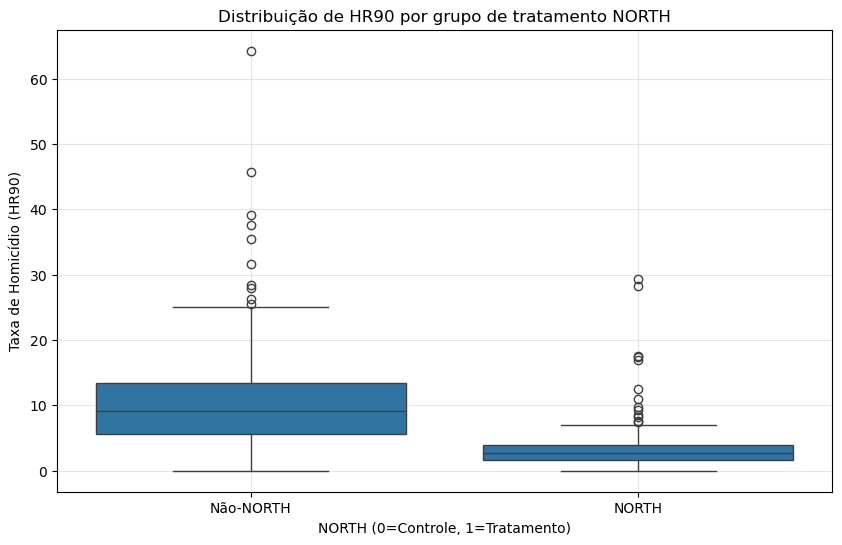

In [10]:
# Separar os grupos
treatment_group = dfs2[dfs2['NORTH'] == 1]['HR90']
control_group = dfs2[dfs2['NORTH'] == 0]['HR90']

# Estatísticas descritivas
print("=== COMPARAÇÃO DE HR90 ENTRE GRUPOS ===")
print(f"Grupo TRATAMENTO (NORTH=1):")
print(f"  N: {len(treatment_group)}")
print(f"  Média HR90: {treatment_group.mean():.4f}")
print(f"  Desvio padrão: {treatment_group.std():.4f}")

print(f"\nGrupo CONTROLE (NORTH=0):")
print(f"  N: {len(control_group)}")
print(f"  Média HR90: {control_group.mean():.4f}")
print(f"  Desvio padrão: {control_group.std():.4f}")

# Diferença de médias
mean_diff = treatment_group.mean() - control_group.mean()
print(f"\nAverage Treatment Effect on the Treated (ATT): {treatment_effect:.4f}")
print(f"Diferença de médias (Tratamento - Controle): {mean_diff:.4f}")

# Teste t para amostras independentes
t_stat, p_value = ttest_ind(treatment_group, control_group, equal_var=False)
print(f"\nTeste t de Welch:")
print(f"  Estatística t: {t_stat:.4f}")
print(f"  Valor-p: {p_value:.4f}")

# Boxplot comparativo
plt.figure(figsize=(10, 6))
sns.boxplot(x='NORTH', y='HR90', data=dfs2)
plt.title('Distribuição de HR90 por grupo de tratamento NORTH')
plt.xlabel('NORTH (0=Controle, 1=Tratamento)')
plt.ylabel('Taxa de Homicídio (HR90)')
plt.xticks([0, 1], ['Não-NORTH', 'NORTH'])
plt.grid(True, alpha=0.3)
plt.show()

# Avançando no PSM: Inverse Probability Weighting (IPW)

O fato de apenas uma pequena porção do grupo de controle ser comparável ao grupo de tratamento (14.7%) é preocupante. Isso sugere que a maioria dos controles não tem características semelhantes aos tratados, o que pode levar a estimativas enviesadas do efeito do tratamento. Isso pode indicar que o modelo de propensão não capturou todas as variáveis relevantes que influenciam a atribuição ao tratamento, ou que os grupos são inerentemente diferentes em aspectos não observados. Para mitigar esse problema, podemos utilizar o método de Inverse Probability Weighting (IPW), que ajusta os pesos das observações com base nos escores de propensão, dando mais peso às observações que são menos prováveis de serem tratadas. Isso ajuda a criar um pseudo-população onde a distribuição das covariáveis é mais equilibrada entre os grupos tratado e controle, melhorando a comparabilidade e a validade das estimativas do efeito do tratamento.

In [11]:
# CALCULAR OS PESOS IPW

# Para ATT (Average Treatment Effect on the Treated)
dfs2['weight'] = np.where(
    dfs2['NORTH'] == 1,  # Tratados
    1,                   # Pesos = 1 para tratados
    dfs2['propensity_score'] / (1 - dfs2['propensity_score'])  # Pesos para controles
)

# Verificar distribuição dos pesos
print("=== ESTATÍSTICAS DOS PESOS IPW ===")
print("Pesos para tratados (NORTH=1):")
print(dfs2[dfs2['NORTH'] == 1]['weight'].describe())
print("\nPesos para controles (NORTH=0):")
print(dfs2[dfs2['NORTH'] == 0]['weight'].describe())

# ESTIMAR ATT USANDO REGRESSÃO PONDERADA
X = sm.add_constant(dfs2[['NORTH', 'RD90', 'PS90', 'UE90', 'FH90']])
y = dfs2['HR90']

# Modelo OLS ponderado pelos pesos IPW
model_ipw = sm.WLS(y, X, weights=dfs2['weight']).fit()

print("\n=== MODELO IPW - ATT ===")
print(f"Coeficiente NORTH (ATT): {model_ipw.params['NORTH']:.4f}")
print(f"Erro padrão: {model_ipw.bse['NORTH']:.4f}")
print(f"Valor-p: {model_ipw.pvalues['NORTH']:.4f}")
print(f"IC 95%: [{model_ipw.conf_int().loc['NORTH', 0]:.4f}, {model_ipw.conf_int().loc['NORTH', 1]:.4f}]")

# ESTIMAR ATE (Average Treatment Effect)
dfs2['weight_ate'] = np.where(
    dfs2['NORTH'] == 1,
    1 / dfs2['propensity_score'],      # Pesos para tratados
    1 / (1 - dfs2['propensity_score']) # Pesos para controles
)

# Modelo para ATE
model_ate = sm.WLS(y, X, weights=dfs2['weight_ate']).fit()

print("\n=== MODELO IPW - ATE ===")
print(f"Coeficiente NORTH (ATE): {model_ate.params['NORTH']:.4f}")
print(f"Erro padrão: {model_ate.bse['NORTH']:.4f}")
print(f"Valor-p: {model_ate.pvalues['NORTH']:.4f}")

# VERIFICAR BALANCEAMENTO APÓS IPW
def check_balance_ipw(data, treatment, covariates, weights):
    """Verifica balanceamento após IPW"""
    print("\n=== BALANCEAMENTO APÓS IPW ===")
    for covar in covariates:
        # Médias ponderadas
        mean_treated = np.average(data[data[treatment] == 1][covar], 
                                weights=weights[data[treatment] == 1])
        mean_control = np.average(data[data[treatment] == 0][covar], 
                                weights=weights[data[treatment] == 0])
        
        # Diferença padronizada
        std_pooled = np.sqrt((data[data[treatment] == 1][covar].var() + 
                            data[data[treatment] == 0][covar].var()) / 2)
        diff_std = (mean_treated - mean_control) / std_pooled
        
        print(f"{covar}:")
        print(f"  Média tratados: {mean_treated:.4f}")
        print(f"  Média controles: {mean_control:.4f}")
        print(f"  Diferença padronizada: {diff_std:.4f}")

check_balance_ipw(dfs2, 'NORTH', ['RD90', 'PS90', 'UE90', 'FH90'], dfs2['weight'])

# RESULTADOS FINAIS
print("\n" + "="*50)
print("COMPARAÇÃO ENTRE MÉTODOS DE ESTIMAÇÃO CAUSAL")
print("="*50)
print(f"PSM (Nearest Neighbor): {treatment_effect:.4f}")
print(f"IPW (ATT): {model_ipw.params['NORTH']:.4f}")
print(f"IPW (ATE): {model_ate.params['NORTH']:.4f}")


=== ESTATÍSTICAS DOS PESOS IPW ===
Pesos para tratados (NORTH=1):
count    211.0
mean       1.0
std        0.0
min        1.0
25%        1.0
50%        1.0
75%        1.0
max        1.0
Name: weight, dtype: float64

Pesos para controles (NORTH=0):
count    5.780000e+02
mean     2.699885e+00
std      4.001756e+01
min      5.821032e-41
25%      9.392967e-11
50%      2.827970e-04
75%      3.699351e-02
max      7.270127e+02
Name: weight, dtype: float64

=== MODELO IPW - ATT ===
Coeficiente NORTH (ATT): -2.8623
Erro padrão: 0.2084
Valor-p: 0.0000
IC 95%: [-3.2713, -2.4533]

=== MODELO IPW - ATE ===
Coeficiente NORTH (ATE): -3.5607
Erro padrão: 0.3544
Valor-p: 0.0000

=== BALANCEAMENTO APÓS IPW ===
RD90:
  Média tratados: -0.7362
  Média controles: -1.8153
  Diferença padronizada: 1.3222
PS90:
  Média tratados: 1.0439
  Média controles: 1.4368
  Diferença padronizada: -0.4556
UE90:
  Média tratados: 6.4429
  Média controles: 3.2241
  Diferença padronizada: 1.3831
FH90:
  Média tratados: 13.2

A análise dos efeitos causais da região nordeste sobre as taxas de homicídio (HR90) indica evidências consistentes de um impacto negativo e estatisticamente significativo. Os métodos de ponderação por probabilidade inversa (IPW) sugerem que residir em uma região classificada como NORTH está associado a uma redução média de cerca de 2,9 homicídios por 100.000 habitantes. Especificamente, o estimador IPW-ATT (efeito médio sobre os tratados) aponta para uma redução de 2,86 homicídios, com valor-p < 0,001 e intervalo de confiança de 95% entre -3,27 e -2,45. O estimador IPW-ATE, que considera o efeito médio sobre toda a população, produz resultado semelhante, estimando uma redução de 3,56 homicídios por 100.000 habitantes se todas as regiões fossem classificadas como NORTH.

Em comparação, o método de Propensity Score Matching (PSM) por vizinho mais próximo produz uma estimativa menor em termos absolutos, de 2,06 homicídios a menos. Essa discrepância sugere que o PSM pode estar capturando vieses de pareamento ou apresentando menor eficiência, enquanto o IPW, por utilizar toda a amostra e distribuir o peso de forma mais equilibrada, tende a fornecer estimativas mais estáveis e confiáveis.

Entretanto, é importante notar que o resultado do balanceamento deixou a desejar. As grandes diferenças padronizadas em RD90 (1.32) e UE90 (1.38) mostram que grupos tratados e controles permanecem fundamentalmente diferentes em características econômicas-chave que provavelmente afetam as taxas de homicídio. O ATT de -2.0638 é potencialmente contaminado por viés de seleção residual. 